# Mall Customers: Segmentación de clientes con K-Means
**Gestión de Proyectos de Datos · Evaluación Parcial N°5 · Parte A (Datos y modelo)**
Integrantes: Antonella Aedo · Carolina Aguirre · Javier Albornoz

Este notebook implementa las fases 2 a 4 de CRISP-DM definidas en el EP3 y deja listos los insumos para la auditoría de equidad (Parte B).

| Entregable EP3 | Requisitos que cubre | Dónde |
|---|---|---|
| **E2** Informe de calidad de datos y conjunto de modelado | RF01, RF02 | Secciones 1 y 2 |
| **E3** Modelo de segmentación e informe de selección de k | RF03, RF04, RF13, RNF04, RNF06 | Secciones 3 a 6 |

Datos: muestra de 200 clientes entregada por el centro comercial (encuestas voluntarias y tarjetas de fidelización). Son datos del cliente y se tratan como confidenciales: en un proyecto real no deben publicarse ni difundirse fuera del equipo. Se incluyen en este repositorio únicamente para efectos de la evaluación académica.

Decisión ética heredada del EP1 y EP3: el modelo se entrena **solo** con `Annual Income` y `Spending Score`. Gender, Age, Education y Marital Status quedan fuera del entrenamiento.

## 0. Configuración (semilla fija, RNF06)

In [1]:
import json, hashlib, datetime, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42                                   # semilla fija: resultados reproducibles
RUTA_DATOS = "Mall Customers.xlsx"          # muestra de datos entregada por el cliente (confidencial)
SALIDAS = Path("outputs"); SALIDAS.mkdir(exist_ok=True)

SENSIBLES = ["Gender", "Age", "Education", "Marital Status"]
VARS_MODELO = ["Annual Income (k$)", "Spending Score (1-100)"]
UMBRAL_SILUETA, UMBRAL_SEG_MIN = 0.40, 5.0  # RNF04
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| semilla", SEED)

pandas 3.0.2 | scikit-learn 1.8.0 | semilla 42


## 1. Carga y validación de datos (RF01 · E2)
Se revisan estructura, nulos, duplicados, rangos y categorías "Unknown".

In [2]:
df = pd.read_excel(RUTA_DATOS)
print("Filas x columnas:", df.shape)

# Hallazgo de calidad: el nombre de la columna 'Education' viene con un espacio al final en el archivo entregado
espacios = [c for c in df.columns if c != c.strip()]
print("Columnas con espacios sobrantes:", [repr(c) for c in espacios])
df.columns = df.columns.str.strip()

calidad = pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "valores_unicos": df.nunique()})
display(calidad)

print("Filas duplicadas:", int(df.duplicated().sum()), "| IDs duplicados:", int(df["CustomerID"].duplicated().sum()))
display(df[["Age", *VARS_MODELO]].agg(["min", "max", "mean"]).round(1))

unknown = {c: round(float((df[c] == "Unknown").mean() * 100), 1) for c in ["Education", "Marital Status"]}
print("% de 'Unknown':", unknown)
print("Distribución de Gender (%):", (df["Gender"].value_counts(normalize=True) * 100).round(1).to_dict())

# Validaciones automáticas: si algo falla, el notebook se detiene
assert df.isna().sum().sum() == 0, "Hay valores nulos"
assert not df["CustomerID"].duplicated().any(), "Hay IDs duplicados"
assert df["Annual Income (k$)"].between(0, 500).all(), "Ingreso fuera de rango"
assert df["Spending Score (1-100)"].between(1, 100).all(), "Spending Score fuera de rango"
print("Validaciones de calidad: OK")

calidad.assign(unknown_pct=pd.Series(unknown)).to_csv(SALIDAS / "E2_informe_calidad.csv")

Filas x columnas: (200, 7)
Columnas con espacios sobrantes: ["'Education '"]


,tipo,nulos,valores_unicos
CustomerID,int64,0,200
Gender,str,0,2
Age,int64,0,51
Education,str,0,7
Marital Status,str,0,4
Annual Income (k$),int64,0,64
Spending Score (1-100),int64,0,84


Filas duplicadas: 0 | IDs duplicados: 0


,Age,Annual Income (k$),Spending Score (1-100)
min,18.0,15.0,1.0
max,70.0,137.0,99.0
mean,38.8,60.6,50.2


% de 'Unknown': {'Education': 13.0, 'Marital Status': 7.5}
Distribución de Gender (%): {'F': 56.0, 'M': 44.0}
Validaciones de calidad: OK


## 2. Conjunto de modelado (RF02, RNF01 · E2)
- Se **excluyen** las variables sensibles.
- Se **seudonimiza** el identificador del cliente (hash con sal).
- Se **estandarizan** ingreso y gasto (media 0, desviación 1), porque K-Means usa distancias.

In [3]:
SAL = "mall-2026"
df["ID_seudonimo"] = df["CustomerID"].astype(str).apply(lambda x: hashlib.sha256((SAL + x).encode()).hexdigest()[:10])

X_raw = df[VARS_MODELO].copy()
assert not set(SENSIBLES) & set(X_raw.columns), "Una variable sensible entró al modelo"

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

modelado = pd.DataFrame(X, columns=["Ingreso_z", "Gasto_z"])
modelado.insert(0, "ID_seudonimo", df["ID_seudonimo"])
modelado.to_csv(SALIDAS / "E2_conjunto_modelado.csv", index=False)

diccionario = pd.DataFrame([
    ["ID_seudonimo", "Identificador seudonimizado (SHA-256 con sal, 10 caracteres)", "texto"],
    ["Ingreso_z", "Annual Income (k$) estandarizado", "numérica"],
    ["Gasto_z", "Spending Score (1-100) estandarizado", "numérica"],
], columns=["variable", "descripción", "tipo"])
display(diccionario)
print("Variables excluidas del entrenamiento:", SENSIBLES)

,variable,descripción,tipo
0,ID_seudonimo,"Identificador seudonimizado (SHA-256 con sal, ...",texto
1,Ingreso_z,Annual Income (k$) estandarizado,numérica
2,Gasto_z,Spending Score (1-100) estandarizado,numérica


Variables excluidas del entrenamiento: ['Gender', 'Age', 'Education', 'Marital Status']


## 3. Selección de k (RF03, RNF04 · E3)
Se entrena K-Means para k = 2 a 8 y se compara por método del codo (inercia), coeficiente de silueta y tamaño del segmento más pequeño.

,k,inercia,silueta,segmento_min_%,cumple_RNF04
0,2,269.69,0.321,38.0,False
1,3,157.70,0.467,19.0,True
2,4,108.92,0.494,11.5,True
3,5,65.57,0.555,11.0,True
4,6,55.06,0.540,5.0,True
5,7,44.86,0.528,5.0,True
6,8,37.23,0.455,5.0,True


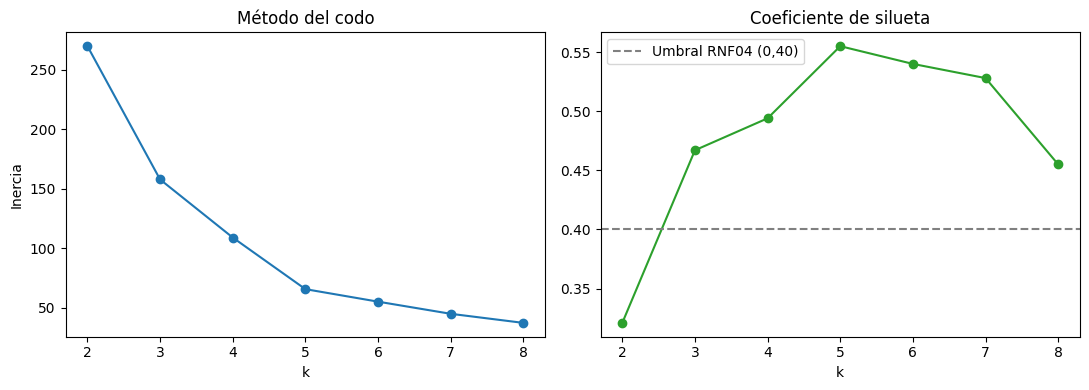

In [4]:
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    tam = np.bincount(km.labels_)
    filas.append({"k": k,
                  "inercia": round(km.inertia_, 2),
                  "silueta": round(silhouette_score(X, km.labels_), 3),
                  "segmento_min_%": round(tam.min() / len(X) * 100, 1)})
seleccion = pd.DataFrame(filas)
seleccion["cumple_RNF04"] = (seleccion["silueta"] >= UMBRAL_SILUETA) & (seleccion["segmento_min_%"] >= UMBRAL_SEG_MIN)
display(seleccion)
seleccion.to_csv(SALIDAS / "E3_seleccion_k.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(seleccion["k"], seleccion["inercia"], "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(seleccion["k"], seleccion["silueta"], "o-", color="tab:green"); ax[1].axhline(UMBRAL_SILUETA, ls="--", color="gray", label="Umbral RNF04 (0,40)")
ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k"); ax[1].legend()
plt.tight_layout(); plt.savefig(SALIDAS / "E3_codo_silueta.png", dpi=150); plt.show()

**Decisión de k.** Se mantiene **k = 5**, el valor planificado en el EP3. La tabla muestra que cumple RNF04 (silueta ≥ 0,40 y segmento mínimo ≥ 5 %) y que en el gráfico del codo la mejora de inercia se aplana desde ese punto.

In [5]:
K = 5
fila = seleccion[seleccion["k"] == K].iloc[0]
assert fila["cumple_RNF04"], "k elegido no cumple RNF04"
mejor = seleccion.loc[seleccion["silueta"].idxmax(), "k"]
print(f"k elegido = {K} | silueta = {fila['silueta']} | segmento mínimo = {fila['segmento_min_%']} % | RNF04: cumple")
print(f"k con mayor silueta en la tabla = {int(mejor)}")

k elegido = 5 | silueta = 0.555 | segmento mínimo = 11.0 % | RNF04: cumple
k con mayor silueta en la tabla = 5


## 4. Modelo final y asignación de segmentos (RF04 · E3/E4)

In [6]:
modelo = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
df["Segmento"] = modelo.labels_

# Se ordenan los segmentos por ingreso promedio para que la numeración sea estable y legible
orden = df.groupby("Segmento")["Annual Income (k$)"].mean().sort_values().index
mapa = {viejo: nuevo + 1 for nuevo, viejo in enumerate(orden)}
df["Segmento"] = df["Segmento"].map(mapa)

def etiqueta(ing, gas):
    i = "bajo" if ing < 40 else ("medio" if ing < 80 else "alto")
    g = "bajo" if gas < 40 else ("medio" if gas <= 60 else "alto")
    return f"Ingreso {i} / Gasto {g}"

fichas = (df.groupby("Segmento")
            .agg(clientes=("CustomerID", "count"),
                 ingreso_prom_k=("Annual Income (k$)", "mean"),
                 gasto_prom=("Spending Score (1-100)", "mean"))
            .round(1))
fichas["% del total"] = (fichas["clientes"] / len(df) * 100).round(1)
fichas["perfil"] = [etiqueta(r.ingreso_prom_k, r.gasto_prom) for r in fichas.itertuples()]
display(fichas)
fichas.to_csv(SALIDAS / "E4_fichas_perfil.csv")

assert df["Segmento"].notna().all()
print("Todos los clientes tienen segmento:", len(df), "clientes")

,clientes,ingreso_prom_k,gasto_prom,% del total,perfil
Segmento,,,,,
1,22,25.7,79.4,11.0,Ingreso bajo / Gasto alto
2,23,26.3,20.9,11.5,Ingreso bajo / Gasto bajo
3,81,55.3,49.5,40.5,Ingreso medio / Gasto medio
4,39,86.5,82.1,19.5,Ingreso alto / Gasto alto
5,35,88.2,17.1,17.5,Ingreso alto / Gasto bajo


Todos los clientes tienen segmento: 200 clientes


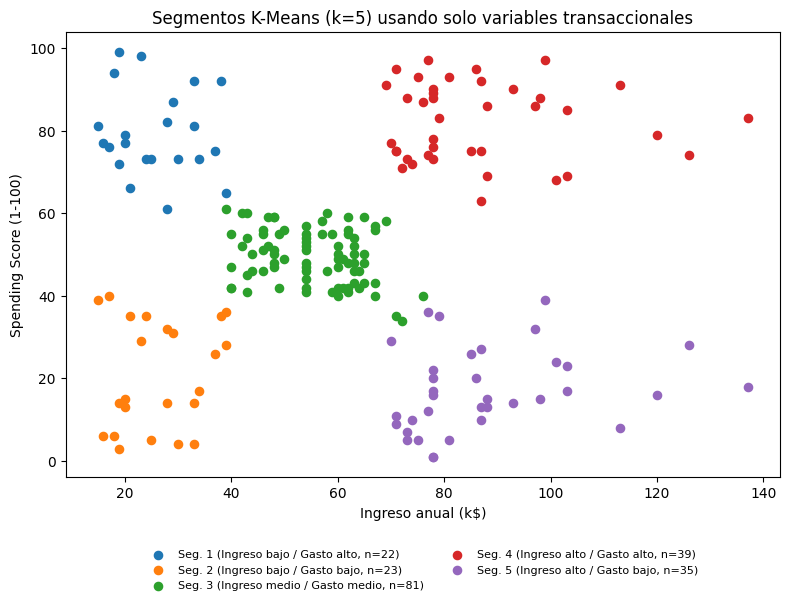

In [7]:
colores = plt.cm.tab10.colors
plt.figure(figsize=(8, 6.2))
for s, g in df.groupby("Segmento"):
    plt.scatter(g["Annual Income (k$)"], g["Spending Score (1-100)"], s=35, color=colores[s - 1], label=f"Seg. {s} ({fichas.loc[s, 'perfil']}, n={len(g)})")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Spending Score (1-100)")
plt.title("Segmentos K-Means (k=5) usando solo variables transaccionales")
plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False); plt.tight_layout()
plt.savefig(SALIDAS / "E3_segmentos.png", dpi=150); plt.show()

## 5. Registro de la ejecución (RF13, RNF06)
Se guarda versión, parámetros y métricas de esta corrida, para poder compararla con reentrenamientos futuros (RF10).

In [8]:
registro = {
    "fecha_ejecucion": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_modelo": "v1.0",
    "algoritmo": "KMeans",
    "parametros": {"k": K, "n_init": 10, "random_state": SEED},
    "variables_entrenamiento": VARS_MODELO,
    "variables_excluidas": SENSIBLES,
    "n_clientes": int(len(df)),
    "metricas": {"silueta": float(fila["silueta"]), "inercia": float(fila["inercia"]),
                 "segmento_min_pct": float(fila["segmento_min_%"]), "cumple_RNF04": bool(fila["cumple_RNF04"])},
    "entorno": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
(SALIDAS / "E3_registro_ejecucion.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(registro, indent=2, ensure_ascii=False))

{
  "fecha_ejecucion": "2026-11-21T20:28:32",
  "version_modelo": "v1.0",
  "algoritmo": "KMeans",
  "parametros": {
    "k": 5,
    "n_init": 10,
    "random_state": 42
  },
  "variables_entrenamiento": [
    "Annual Income (k$)",
    "Spending Score (1-100)"
  ],
  "variables_excluidas": [
    "Gender",
    "Age",
    "Education",
    "Marital Status"
  ],
  "n_clientes": 200,
  "metricas": {
    "silueta": 0.555,
    "inercia": 65.57,
    "segmento_min_pct": 11.0,
    "cumple_RNF04": true
  },
  "entorno": {
    "python": "3.13.1",
    "scikit-learn": "1.8.0",
    "pandas": "3.0.2"
  }
}


## 6. Exportación para la Parte B (auditoría de equidad)
El archivo trae `CustomerID` y `Segmento`, de modo que la Parte B pueda cruzarlo con Gender, Age, Education y Marital Status para auditar la paridad demográfica (RF05, RNF03). Esas variables **no** participaron en el entrenamiento.

In [9]:
df[["CustomerID", "ID_seudonimo", "Segmento"]].to_csv(SALIDAS / "E3_segmentos_clientes.csv", index=False)
print("Archivos generados en", SALIDAS.resolve())
for p in sorted(SALIDAS.iterdir()):
    print(" -", p.name)

Archivos generados en C:\Users\aguir\Desktop\EP5 Parte A - Mall Customers\outputs
 - E2_conjunto_modelado.csv
 - E2_informe_calidad.csv
 - E3_codo_silueta.png
 - E3_registro_ejecucion.json
 - E3_segmentos.png
 - E3_segmentos_clientes.csv
 - E3_seleccion_k.csv
 - E4_fichas_perfil.csv
